<a href="https://colab.research.google.com/github/MuhammadAmaan178/Demand-Lens/blob/main/notebooks/DLens_08_AnomalyDetection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Notebook 08: Anomaly Detection (Store CA_1)
## Step 1: Import Libraries, Mount Drive, and Verify Files

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
import joblib
import json

In [ ]:
import os
from google.colab import drive

# Mount Google Drive
drive.mount("/content/drive")

# Set folder paths
BASE_DIR = "/content/drive/MyDrive/DemandLens"
EXPORT_DIR = os.path.join(BASE_DIR, "Data", "processed")

# Model and data file paths
MODEL_PATH = os.path.join(EXPORT_DIR, "lightgbm_h7.joblib")
TRAIN_PATH = os.path.join(EXPORT_DIR, "ca1_h7_train.parquet")
VAL_PATH = os.path.join(EXPORT_DIR, "ca1_h7_val.parquet")
FEATURES_PATH = os.path.join(EXPORT_DIR, "feature_lists.json")

# Check if all required files exist
files = {
    "Model": MODEL_PATH,
    "Training Data": TRAIN_PATH,
    "Validation Data": VAL_PATH,
    "Feature Lists": FEATURES_PATH
}

for name, path in files.items():
    if os.path.exists(path):
        print(f"{name}: Found")
    else:
        print(f"{name}: Not Found")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Model: Found
Training Data: Found
Validation Data: Found
Feature Lists: Found


## Step 2: Load Model, Feature Lists, and Datasets

### What we are doing in this cell
We are loading the trained H7 LightGBM model, `feature_lists.json`, and the training and validation datasets from Google Drive, then inspecting their shapes, date ranges, and missing values.

### Why we need this step
Confirming dataset dimensions, clean date boundaries (no leakage between train and validation), and zero missing values ensures the pipeline runs smoothly.

### What output we should expect
Model type, JSON feature counts, dataset shapes, date ranges, column names, and missing value counts.

In [ ]:
# Load model and feature lists
model_h7 = joblib.load(MODEL_PATH)

with open(FEATURES_PATH, "r") as f:
    feature_lists = json.load(f)

print("Model:", type(model_h7))
print("\nFeature Lists:")
for name, values in feature_lists.items():
    print(name, ":", len(values) if isinstance(values, list) else values)

Model: <class 'lightgbm.sklearn.LGBMRegressor'>

Feature Lists:
features_7 : 27
features_28 : 27
item_categories : 3049


In [ ]:
# Load training and validation data
train_df = pd.read_parquet(TRAIN_PATH)
val_df = pd.read_parquet(VAL_PATH)

In [ ]:
train_df.shape, val_df.shape

((4552041, 26), (85372, 26))

In [ ]:
val_df.columns

Index(['item_id', 'store_id', 'date', 'sales', 'lag_7', 'rolling_mean_7',
       'wday', 'month', 'year', 'is_weekend', 'snap', 'has_event',
       'sell_price', 'price_change', 'ev_Cultural', 'ev_National',
       'ev_Religious', 'ev_Sporting', 'ev_None', 'dept_FOODS_1',
       'dept_FOODS_2', 'dept_FOODS_3', 'dept_HOBBIES_1', 'dept_HOBBIES_2',
       'dept_HOUSEHOLD_1', 'dept_HOUSEHOLD_2'],
      dtype='object')

In [ ]:
# Check date ranges
print("\nTrain Date Range:", train_df["date"].min(), "to", train_df["date"].max())
print("Validation Date Range:", val_df["date"].min(), "to", val_df["date"].max())


Train Date Range: 2011-02-09 00:00:00 to 2016-03-27 00:00:00
Validation Date Range: 2016-03-28 00:00:00 to 2016-04-24 00:00:00


In [ ]:
# Check missing values
print("Training Missing Values:")
print(train_df.isnull().sum().sum())

print("\nValidation Missing Values:")
print(val_df.isnull().sum().sum())

Training Missing Values:
0

Validation Missing Values:
0


## Step 3: Verify Required Model Features

### What we are doing
We will check which features are required by `model_h7` and compare them with the features in `features_7` and the columns available in `val_df`.

### Why we need this step
Our validation dataset has 26 columns, while `features_7` contains 27 features. We need to identify any missing columns and check whether features have the correct data types.

### Expected Output
- Features expected by the model.
- Features listed in `features_7`.
- Any missing columns in `val_df`.

This will help us avoid feature mismatch errors when making predictions.

In [ ]:
# Get feature list
features_7 = feature_lists["features_7"]

print("Features in features_7:", len(features_7))
print(features_7)


# Get features expected by the model
model_features = list(model_h7.feature_name_)

print("\nFeatures expected by model:", len(model_features))
print(model_features)


Features in features_7: 27
['item_id', 'lag_7', 'rolling_mean_7', 'wday', 'month', 'year', 'is_weekend', 'snap', 'has_event', 'sell_price', 'price_change', 'ev_Cultural', 'ev_National', 'ev_Religious', 'ev_Sporting', 'ev_None', 'dept_FOODS_1', 'dept_FOODS_2', 'dept_FOODS_3', 'dept_HOBBIES_1', 'dept_HOBBIES_2', 'dept_HOUSEHOLD_1', 'dept_HOUSEHOLD_2', 'wday_sin', 'wday_cos', 'month_sin', 'month_cos']

Features expected by model: 27
['item_id', 'lag_7', 'rolling_mean_7', 'wday', 'month', 'year', 'is_weekend', 'snap', 'has_event', 'sell_price', 'price_change', 'ev_Cultural', 'ev_National', 'ev_Religious', 'ev_Sporting', 'ev_None', 'dept_FOODS_1', 'dept_FOODS_2', 'dept_FOODS_3', 'dept_HOBBIES_1', 'dept_HOBBIES_2', 'dept_HOUSEHOLD_1', 'dept_HOUSEHOLD_2', 'wday_sin', 'wday_cos', 'month_sin', 'month_cos']


In [ ]:
# Check missing features in validation data
missing_features = [col for col in model_features if col not in val_df.columns]

print("\nMissing Features:", missing_features if missing_features else "None")



Missing Features: ['wday_sin', 'wday_cos', 'month_sin', 'month_cos']


## Step 4: Generate Validation Predictions, Residuals, and WAPE

### What we are doing
We will recreate the four missing cyclical features (`wday_sin`, `wday_cos`, `month_sin`, `month_cos`) using the existing `wday` and `month` columns. Then, we will use our trained LightGBM model to predict sales for the next 7 days.

We will also calculate residuals (actual sales - predicted sales) and evaluate the model using WAPE, MAE, and RMSE.

### Why we need this step
We need to compare actual sales with predicted sales to identify unusual differences. These differences will help us detect anomalies.

### Expected Output
- Validation WAPE, MAE, and RMSE.
- No negative sales predictions.
- A new `residual` column.
- First 5 rows showing `item_id`, `date`, `sales`, `forecast`, and `residual`.

In [ ]:
# Recreate missing cyclical features
val_df["wday_sin"] = np.sin(2 * np.pi * val_df["wday"] / 7)
val_df["wday_cos"] = np.cos(2 * np.pi * val_df["wday"] / 7)
val_df["month_sin"] = np.sin(2 * np.pi * val_df["month"] / 12)
val_df["month_cos"] = np.cos(2 * np.pi * val_df["month"] / 12)

In [ ]:
# Set item_id as categorical
val_df["item_id"] = pd.Categorical(
    val_df["item_id"],
    categories=feature_lists["item_categories"]
)

In [ ]:
# Select model features and generate predictions
X_val = val_df[model_features]
predictions = model_h7.predict(X_val)

val_df["forecast"] = np.clip(predictions, 0, None)

In [ ]:
# Calculate residuals
val_df["residual"] = val_df["sales"] - val_df["forecast"]

In [ ]:
# Calculate evaluation metrics
wape = np.abs(val_df["residual"]).sum() / val_df["sales"].sum() * 100
mae = np.abs(val_df["residual"]).mean()
rmse = np.sqrt((val_df["residual"] ** 2).mean())

print("Validation WAPE:", round(wape, 2), "%")
print("Validation MAE:", round(mae, 4))
print("Validation RMSE:", round(rmse, 4))

Validation WAPE: 73.51 %
Validation MAE: 1.1017
Validation RMSE: 2.1367


In [ ]:
# Display predictions
val_df[["item_id", "date", "sales", "forecast", "residual"]].head()

,item_id,date,sales,forecast,residual
0,FOODS_1_001,2016-03-28,2,0.694105,1.305895
1,FOODS_1_001,2016-03-29,1,0.890745,0.109255
2,FOODS_1_001,2016-03-30,1,0.994175,0.005825
3,FOODS_1_001,2016-03-31,0,0.949817,-0.949817
4,FOODS_1_001,2016-04-01,4,1.103135,2.896865


## Step 5: Rule-Based Anomaly Detection (Validation Data)

### What we are doing
We will identify unusual sales days by comparing actual sales with predicted sales.

A day will be marked as an anomaly only when both conditions are met:

1. Absolute residual is greater than 3 times the standard deviation of residuals.
2. Absolute residual is greater than 3 units.

We will also classify anomalies into two types:
- **Spike:** Actual sales are much higher than predicted sales.
- **Drop:** Actual sales are much lower than predicted sales.

### Why we need this step
Small differences between actual and predicted sales are normal in retail. These two conditions help us ignore small errors and focus on more significant sales changes.

### Expected Output
- Standard deviation of residuals (normal error).
- 3x error threshold.
- Total number and percentage of anomalies.
- Number of spikes and drops.
- Top 5 largest anomalies.

In [ ]:
# Calculate normal error and thresholds
normal_error = val_df["residual"].std()
threshold_3x = 3 * normal_error
min_unit_threshold = 3.0

print("Normal Error:", round(normal_error, 4))
print("3x Threshold:", round(threshold_3x, 4))
print("Minimum Unit Threshold:", min_unit_threshold)

Normal Error: 2.1367
3x Threshold: 6.4101
Minimum Unit Threshold: 3.0


In [ ]:
# Calculate absolute residual
val_df["abs_residual"] = val_df["residual"].abs()

In [ ]:
# Flag anomalies using both conditions
val_df["rule_anomaly"] = (
    (val_df["abs_residual"] > threshold_3x) &
    (val_df["abs_residual"] > min_unit_threshold)
)

In [ ]:
# Classify anomalies
val_df["rule_direction"] = "normal"

val_df.loc[val_df["rule_anomaly"] & (val_df["residual"] > 0), "rule_direction"] = "spike"
val_df.loc[val_df["rule_anomaly"] & (val_df["residual"] < 0), "rule_direction"] = "drop"

In [ ]:
# Calculate anomaly summary
total_rows = len(val_df)
total_anomalies = val_df["rule_anomaly"].sum()
anomaly_pct = total_anomalies / total_rows * 100

spikes = (val_df["rule_direction"] == "spike").sum()
drops = (val_df["rule_direction"] == "drop").sum()

print("\nTotal Rows:", total_rows)
print("Total Anomalies:", total_anomalies)
print("Anomaly Percentage:", round(anomaly_pct, 2), "%")
print("Spikes:", spikes)
print("Drops:", drops)


Total Rows: 85372
Total Anomalies: 1416
Anomaly Percentage: 1.66 %
Spikes: 938
Drops: 478


In [ ]:
# Display top 5 largest anomalies
top_anomalies = val_df[val_df["rule_anomaly"]].sort_values(
    "abs_residual", ascending=False
)

top_anomalies[["item_id", "date", "sales", "forecast", "residual", "rule_direction"]].head(5)

,item_id,date,sales,forecast,residual,rule_direction
68803,HOUSEHOLD_1_465,2016-04-04,82,7.693125,74.306875,spike
20509,FOODS_3_120,2016-04-10,0,71.443632,-71.443632,drop
20502,FOODS_3_120,2016-04-03,126,58.601518,67.398482,spike
31083,FOODS_3_498,2016-03-31,64,0.853590,63.146410,spike
25397,FOODS_3_295,2016-03-29,78,19.721551,58.278449,spike


## Step 6: Isolation Forest Anomaly Detection & Method Comparison

### What we are doing
We will train an Isolation Forest model using 7 features: `sales`, `forecast`, `residual`, `price_change`, `has_event`, `snap`, and `is_weekend`.

We will use `contamination=0.01` and `random_state=42` to detect unusual sales patterns.

Then, we will compare its results with our rule-based method and classify each row into four categories:

- **Both:** Flagged by both methods.
- **Rule:** Flagged only by the rule-based method.
- **Isolation:** Flagged only by Isolation Forest.
- **None:** Not flagged by either method.

### Why we need this step
Our rule-based method mainly looks at residual size, while Isolation Forest considers multiple features together to identify unusual sales patterns.

For example, it may detect an unusual sales drop along with a price change or SNAP activity.

### Why this comparison is important
It allows us to compare two different anomaly detection methods. If both methods flag the same day, it becomes a stronger signal that the day needs further investigation.

### Expected Output
- Total anomalies detected by Isolation Forest.
- Comparison of both methods (`both`, `rule`, `isolation`, and `none`).
- Top 5 anomalies detected by both methods.

In [ ]:
from sklearn.ensemble import IsolationForest

In [ ]:
# Select features for Isolation Forest
iso_features = [
    "sales",
    "forecast",
    "residual",
    "price_change",
    "has_event",
    "snap",
    "is_weekend"
]

In [ ]:
# Train Isolation Forest
iso_model = IsolationForest(
    contamination=0.01,
    random_state=42,
    n_jobs=-1
)

In [ ]:
iso_preds = iso_model.fit_predict(val_df[iso_features])

In [ ]:
# Mark anomalies
val_df["iso_anomaly"] = iso_preds == -1

In [ ]:
# Compare both methods
val_df["flagged_by"] = "none"

val_df.loc[val_df["rule_anomaly"] & ~val_df["iso_anomaly"], "flagged_by"] = "rule"
val_df.loc[~val_df["rule_anomaly"] & val_df["iso_anomaly"], "flagged_by"] = "isolation"
val_df.loc[val_df["rule_anomaly"] & val_df["iso_anomaly"], "flagged_by"] = "both"

In [ ]:
# Display anomaly summary
print("Isolation Forest Anomalies:", val_df["iso_anomaly"].sum())
print("\nComparison of Both Methods:")
print(val_df["flagged_by"].value_counts())

Isolation Forest Anomalies: 853

Comparison of Both Methods:
flagged_by
none         83594
rule           925
both           491
isolation      362
Name: count, dtype: int64


In [ ]:
# Display top 5 anomalies detected by both methods
both_df = val_df[val_df["flagged_by"] == "both"].sort_values(
    "abs_residual", ascending=False
)

both_df[["item_id", "date", "sales", "forecast", "residual",
         "price_change", "has_event", "snap"]].head(5)

,item_id,date,sales,forecast,residual,price_change,has_event,snap
68803,HOUSEHOLD_1_465,2016-04-04,82,7.693125,74.306875,0.0,0,1
20509,FOODS_3_120,2016-04-10,0,71.443632,-71.443632,0.0,0,1
20502,FOODS_3_120,2016-04-03,126,58.601518,67.398482,0.0,0,1
31083,FOODS_3_498,2016-03-31,64,0.853590,63.146410,0.0,0,0
25397,FOODS_3_295,2016-03-29,78,19.721551,58.278449,0.0,0,0


## Step 7: K-Means Item Grouping — Compare K=3, 4, and 5

### What we are doing
Using training data only, we will calculate four features for each of the 3,049 items:

1. `avg_sales`: Average daily sales.
2. `zero_sales_share`: Percentage of days with zero sales.
3. `sales_std`: Variation in daily sales.
4. `weekend_sales_ratio`: Weekend sales compared to total sales.

Next, we will scale these features using `StandardScaler` and apply K-Means clustering with K = 3, 4, and 5.

We will compare the results using Silhouette Scores.

### Why we need this step
Different items have different sales patterns. For example, fast-selling items and slow-selling items should not have the same anomaly thresholds.

Grouping similar items helps us create more suitable anomaly thresholds for each group.

### Expected Output
- Shape of the item-level feature table.
- Preview of the first 5 items.
- Silhouette Scores for K = 3, 4, and 5.

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [ ]:
# Create item-level features using training data
train_weekend_sales = train_df["sales"] * train_df["is_weekend"]

grouped = train_df.groupby("item_id", observed=True)

item_features = pd.DataFrame({
    "avg_sales": grouped["sales"].mean(),
    "zero_sales_share": grouped["sales"].apply(lambda x: (x == 0).mean()),
    "sales_std": grouped["sales"].std().fillna(0),
    "total_sales": grouped["sales"].sum()
})

weekend_totals = train_weekend_sales.groupby(
    train_df["item_id"], observed=True
).sum()

item_features["weekend_sales_ratio"] = np.where(
    item_features["total_sales"] > 0,
    weekend_totals / item_features["total_sales"],
    0
)

item_features = item_features.drop(columns="total_sales").reset_index()

In [ ]:
# Display item features
print("Item Feature Table Shape:", item_features.shape)
item_features.head()

Item Feature Table Shape: (3049, 5)


,item_id,avg_sales,zero_sales_share,sales_std,weekend_sales_ratio
0,FOODS_1_001,0.780579,0.565451,1.258201,0.355326
1,FOODS_1_002,0.480945,0.667203,0.807814,0.314732
2,FOODS_1_003,0.837634,0.527957,1.169582,0.318357
3,FOODS_1_004,10.672367,0.123119,8.629497,0.351855
4,FOODS_1_005,1.156116,0.541309,2.019971,0.349420


In [ ]:
# Scale features
cluster_cols = [
    "avg_sales",
    "zero_sales_share",
    "sales_std",
    "weekend_sales_ratio"
]

In [ ]:
scaler = StandardScaler()
X_items_scaled = scaler.fit_transform(item_features[cluster_cols])

In [ ]:
# Compare K-Means for K = 3, 4, and 5
silhouette_scores = {}

for k in [3, 4, 5]:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_items_scaled)

    score = silhouette_score(X_items_scaled, labels)
    silhouette_scores[k] = score

    print(f"K = {k}, Silhouette Score = {score:.4f}")

K = 3, Silhouette Score = 0.3464
K = 4, Silhouette Score = 0.3299
K = 5, Silhouette Score = 0.3390


In [ ]:
# Find the best K
best_k = max(silhouette_scores, key=silhouette_scores.get)

print("\nBest K:", best_k)
print("Best Silhouette Score:", round(silhouette_scores[best_k], 4))


Best K: 3
Best Silhouette Score: 0.3464


## Step 8: Final K-Means Grouping & Group-Specific Anomaly Thresholds

### What we are doing
We will train our final K-Means model using `K = 3` and group the items into three categories based on their average daily sales:

- **Slow Sellers**
- **Medium Sellers**
- **Fast Sellers**

Then, we will add these groups to our validation data and calculate a separate anomaly threshold for each group using 3 times its residual standard deviation, with a minimum threshold of 3 units.

### Why we need this step
Different items have different sales patterns. A single anomaly threshold may be too strict for fast-selling items and too loose for slow-selling items.

Using separate thresholds helps us identify unusual sales more fairly.

### Expected Output
- Summary of the three item groups, including item counts and average features.
- Separate anomaly thresholds for each group.
- Updated anomaly counts using group-specific thresholds.

In [ ]:
# Train final K-Means model with K = 3
kmeans_model = KMeans(n_clusters=best_k, random_state=42, n_init=10)
item_features["cluster_id"] = kmeans_model.fit_predict(X_items_scaled)

In [ ]:
# Name groups based on average sales
cluster_order = (
    item_features.groupby("cluster_id")["avg_sales"]
    .mean()
    .sort_values()
    .index
)

group_names = ["Slow Sellers", "Medium Sellers", "Fast Sellers"]
cluster_name_map = dict(zip(cluster_order, group_names))

item_features["group"] = item_features["cluster_id"].map(cluster_name_map)

In [ ]:
# Display group summary
group_summary = item_features.groupby("group")[cluster_cols].mean()
group_summary["item_count"] = item_features.groupby("group")["item_id"].count()

print("Item Group Summary:")
group_summary.loc[group_names]

Item Group Summary:


,avg_sales,zero_sales_share,sales_std,weekend_sales_ratio,item_count
group,,,,,
Slow Sellers,0.498327,0.704506,0.887154,0.363165,1910
Medium Sellers,2.561998,0.321281,2.646979,0.361692,1078
Fast Sellers,16.859259,0.157668,13.494834,0.360786,61


In [ ]:
# Add item groups to validation data
item_group_map = item_features.set_index("item_id")["group"]
val_df["group"] = val_df["item_id"].map(item_group_map)

In [ ]:
# Calculate thresholds for each group
group_thresholds = (
    val_df.groupby("group")["residual"]
    .std()
    .reset_index(name="normal_error_std")
)

group_thresholds["threshold_3x"] = 3 * group_thresholds["normal_error_std"]
group_thresholds["effective_threshold"] = np.maximum(
    group_thresholds["threshold_3x"], 3.0
)

print("\nGroup-Specific Thresholds:")
print(group_thresholds)


Group-Specific Thresholds:
            group  normal_error_std  threshold_3x  effective_threshold
0    Fast Sellers          8.484099     25.452298            25.452298
1  Medium Sellers          2.674156      8.022468             8.022468
2    Slow Sellers          0.966273      2.898819             3.000000


In [ ]:
# Apply group-specific thresholds
thresh_map = group_thresholds.set_index("group")["effective_threshold"]
val_df["group_threshold"] = val_df["group"].map(thresh_map)

val_df["rule_anomaly"] = val_df["abs_residual"] > val_df["group_threshold"]

In [ ]:
# Combine rule-based and Isolation Forest results
val_df["flagged_by"] = "none"

val_df.loc[val_df["rule_anomaly"] & ~val_df["iso_anomaly"], "flagged_by"] = "rule"
val_df.loc[~val_df["rule_anomaly"] & val_df["iso_anomaly"], "flagged_by"] = "isolation"
val_df.loc[val_df["rule_anomaly"] & val_df["iso_anomaly"], "flagged_by"] = "both"

val_df["is_anomaly"] = val_df["flagged_by"] != "none"

In [ ]:
# Classify anomalies as spikes or drops
val_df["direction"] = "normal"

val_df.loc[val_df["is_anomaly"] & (val_df["residual"] > 0), "direction"] = "spike"
val_df.loc[val_df["is_anomaly"] & (val_df["residual"] < 0), "direction"] = "drop"

In [ ]:
# Display final anomaly summary
print("\nAnomaly Summary:")
print(val_df["flagged_by"].value_counts())

print("\nTotal Anomalies:", val_df["is_anomaly"].sum())


Anomaly Summary:
flagged_by
none         83354
rule          1165
isolation      666
both           187
Name: count, dtype: int64

Total Anomalies: 2018


## **Step 9: Hierarchical Clustering, Dendrogram & Comparison with K-Means**

### **What we are doing**

We are applying **Hierarchical Clustering (Ward's method)** to the same scaled item data (`X_items_scaled`). We will plot a dendrogram, create 3 clusters, and compare them with K-Means.

### **Why we need this step**

To check whether Hierarchical Clustering finds similar item groups to K-Means.

### **What problem this solves**

It helps us check if our 3 item groups have meaningful patterns and are not just a result of one algorithm.

### **Expected output**

- A dendrogram showing how items merge into clusters.
- Silhouette Score comparison of both methods.
- A table comparing how both methods grouped all 3,049 items.

**Final choice:** We will keep K-Means because it is faster and easier to save and use for new items.

In [ ]:
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

In [ ]:
# Apply Hierarchical Clustering using Ward's method
linkage_matrix = linkage(X_items_scaled, method="ward")

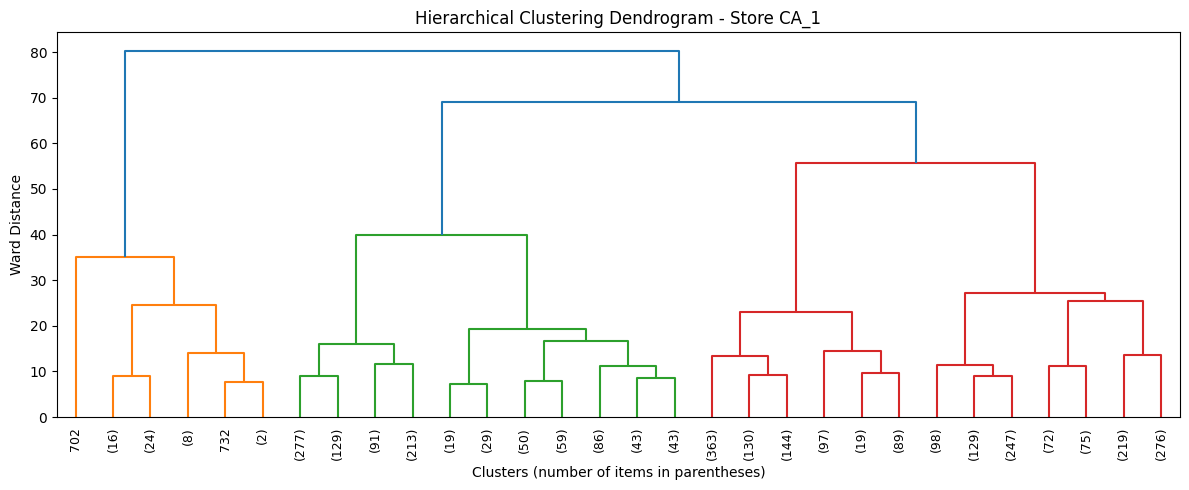

In [ ]:
# Plot the dendrogram to visualize how items are grouped
plt.figure(figsize=(12, 5))

dendrogram(
    linkage_matrix,
    truncate_mode="lastp",
    p=30,                  # Show only the last 30 merged clusters
    leaf_rotation=90,
    leaf_font_size=9
)

plt.title("Hierarchical Clustering Dendrogram - Store CA_1")
plt.xlabel("Clusters (number of items in parentheses)")
plt.ylabel("Ward Distance")
plt.tight_layout()
plt.show()


In [ ]:
# Divide all items into the same number of clusters as K-Means
hier_labels = fcluster(linkage_matrix, t=best_k, criterion="maxclust")

In [ ]:
# Save the Hierarchical Clustering groups
item_features["hier_cluster"] = hier_labels

In [ ]:
# Calculate Silhouette Scores for both clustering methods
hier_sil = silhouette_score(X_items_scaled, hier_labels)
kmeans_sil = silhouette_scores[best_k]

print("\n--- K-Means vs Hierarchical Clustering ---")
print(f"K-Means Silhouette Score:      {kmeans_sil:.4f}")
print(f"Hierarchical Silhouette Score: {hier_sil:.4f}")


--- K-Means vs Hierarchical Clustering ---
K-Means Silhouette Score:      0.3464
Hierarchical Silhouette Score: 0.3057


In [ ]:
# Compare how both methods grouped the items
comparison_table = pd.crosstab(
    item_features["group"],
    item_features["hier_cluster"],
    margins=True
)

print("Cluster Comparison Table:")
print(comparison_table)

# Keep K-Means as our final clustering method
print("Final Decision: Keeping K-Means for item grouping.")

Cluster Comparison Table:
hier_cluster     1     2     3   All
group                               
Fast Sellers    52     9     0    61
Medium Sellers   0   884   194  1078
Slow Sellers     0   146  1764  1910
All             52  1039  1958  3049
Final Decision: Keeping K-Means for item grouping.


## **Step 10: Assign Possible Anomaly Reasons**

### **What we are doing**

We are assigning a reason to each flagged anomaly in the validation data based on this priority:

1. **Price Change**
2. **Event**
3. **SNAP Day**
4. **Unexplained** (if no other condition matches)

Normal days will be labeled as `"None"`.

### **Why we need this step**

It helps store managers understand the possible reason behind an unusual sales day instead of just seeing an anomaly alert.

### **What problem this solves**

It adds useful business context to anomaly alerts. These reasons are only possible hints, not confirmed causes.

### **Expected output**

- Count and percentage of each anomaly reason.
- A preview of 10 flagged anomalies with their assigned reasons.

In [ ]:
# Step 10: Assign Possible Reasons to Anomalies

# Create a function to assign a reason to each anomaly
def assign_anomaly_reasons(df):

    conditions = [
        ~df["is_anomaly"],          # Normal day
        df["price_change"] != 0,    # Price change
        df["has_event"] == 1,       # Event day
        df["snap"] == 1             # SNAP day
    ]

    reasons = [
        "None",
        "Price change",
        "Event",
        "SNAP day"
    ]

    # Assign a reason based on the first matching condition
    return np.select(conditions, reasons, default="Unexplained")

In [ ]:
# Apply the function to validation data
val_df["reason"] = assign_anomaly_reasons(val_df)


# Select only the flagged anomalies
anomalies_only = val_df[val_df["is_anomaly"]]

print("--- Anomaly Reason Breakdown ---")
print(f"Total Flagged Anomalies: {len(anomalies_only):,}\n")

--- Anomaly Reason Breakdown ---
Total Flagged Anomalies: 2,018



In [ ]:
# Calculate the count and percentage of each reason
reason_counts = anomalies_only["reason"].value_counts()

for reason, count in reason_counts.items():
    percentage = (count / len(anomalies_only)) * 100
    print(f"{reason:<15}: {count:>5,} ({percentage:.2f}%)")

Unexplained    : 1,121 (55.55%)
SNAP day       :   888 (44.00%)
Price change   :     9 (0.45%)


In [ ]:
# Display a sample of 10 flagged anomalies
print("Sample Anomalies with Possible Reasons:")

display_cols = [
    "item_id", "date", "sales", "forecast",
    "residual", "direction", "group", "flagged_by", "reason"
]

display(anomalies_only[display_cols].head(10))


print("Note: These reasons are possible hints, not confirmed causes.")

Sample Anomalies with Possible Reasons:


,item_id,date,sales,forecast,residual,direction,group,flagged_by,reason
7,FOODS_1_001,2016-04-04,4,0.923384,3.076616,spike,Slow Sellers,rule,SNAP day
21,FOODS_1_001,2016-04-18,4,0.885024,3.114976,spike,Slow Sellers,rule,Unexplained
56,FOODS_1_003,2016-03-28,4,0.740433,3.259567,spike,Slow Sellers,rule,Unexplained
254,FOODS_1_011,2016-03-30,4,0.153791,3.846209,spike,Slow Sellers,rule,Unexplained
447,FOODS_1_017,2016-04-24,4,0.917930,3.082070,spike,Slow Sellers,rule,Unexplained
453,FOODS_1_018,2016-04-02,16,16.979145,-0.979145,drop,Medium Sellers,isolation,SNAP day
454,FOODS_1_018,2016-04-03,16,15.012317,0.987683,spike,Medium Sellers,isolation,SNAP day
458,FOODS_1_018,2016-04-07,2,12.417914,-10.417914,drop,Medium Sellers,rule,SNAP day
460,FOODS_1_018,2016-04-09,5,13.641409,-8.641409,drop,Medium Sellers,rule,SNAP day
473,FOODS_1_018,2016-04-22,25,6.895599,18.104401,spike,Medium Sellers,both,Unexplained


Note: These reasons are possible hints, not confirmed causes.


## **Step 11: Visualizations — Daily Anomalies, Reasons, and Silhouette Scores**

### **What we are doing**

We are creating three charts:

1. **Anomalies per Day:** Shows the number of flagged items each day.
2. **Anomaly Reasons:** Shows how many anomalies belong to each possible reason.
3. **Silhouette Scores:** Compares K-Means clustering quality for K = 3, 4, and 5.

### **Why we need this step**

Charts make it easier to understand patterns and identify trends that may not be obvious in tables.

### **What problem this solves**

It turns our results into clear visual insights that can be used in project reports, presentations, and the DemandLens dashboard.

### **Expected output**

Three separate charts showing daily anomaly counts, possible anomaly reasons, and K-Means Silhouette Score comparisons.

In [ ]:
# Step 11: Visualize Anomalies, Reasons, and Silhouette Scores
sns.set_style("whitegrid")

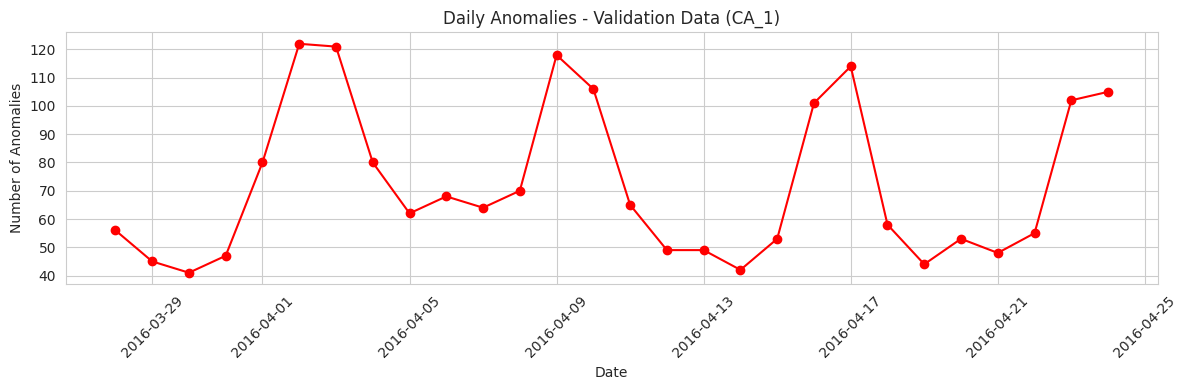

In [ ]:
# 1. Plot the number of anomalies per day
anomalies_per_day = (
    val_df[val_df["is_anomaly"]]
    .groupby("date")
    .size()
)

plt.figure(figsize=(12, 4))

plt.plot(
    anomalies_per_day.index,
    anomalies_per_day.values,
    marker="o",
    color="red"
)

plt.title("Daily Anomalies - Validation Data (CA_1)")
plt.xlabel("Date")
plt.ylabel("Number of Anomalies")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

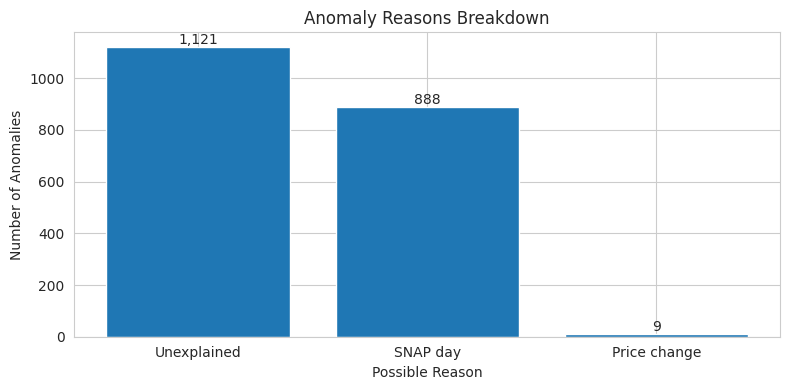

In [ ]:
# 2. Plot the breakdown of possible anomaly reasons
reason_counts = val_df[val_df["is_anomaly"]]["reason"].value_counts()

plt.figure(figsize=(8, 4))

bars = plt.bar(reason_counts.index, reason_counts.values)

plt.title("Anomaly Reasons Breakdown")
plt.xlabel("Possible Reason")
plt.ylabel("Number of Anomalies")

# Show the count above each bar
for bar in bars:
    count = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        count,
        f"{int(count):,}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

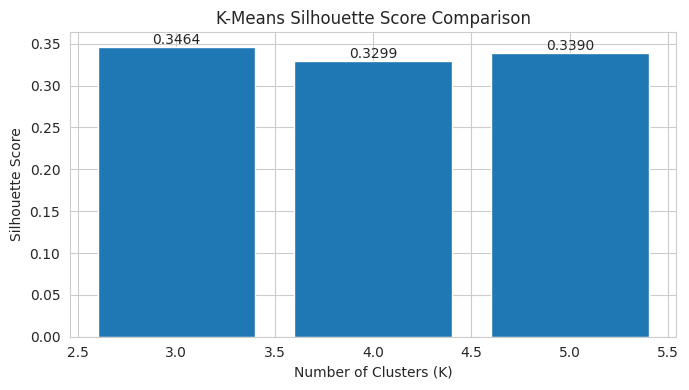

In [ ]:
# 3. Compare K-Means Silhouette Scores for different K values
k_list = list(silhouette_scores.keys())
score_list = list(silhouette_scores.values())

plt.figure(figsize=(7, 4))

bars = plt.bar(k_list, score_list)

plt.title("K-Means Silhouette Score Comparison")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")

# Show the score above each bar
for bar in bars:
    score = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        score,
        f"{score:.4f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

## **Step 12: Visualizations — Three Sample Item Sales Charts with Anomalies**

### **What we are doing**

We are selecting three sample items: one from **Fast Sellers**, one from **Medium Sellers**, and one from **Slow Sellers**.

For each item, we will plot:

- Actual daily sales (blue line).
- 7-day LightGBM forecast (orange dashed line).
- Flagged anomalies (red dots).

### **Why we need this step**

It helps us visually check whether our anomaly detection is identifying unusual sales spikes and sudden drops.

### **What problem this step solves**

It provides a final visual check of our group-based thresholds and Isolation Forest results before exporting data for the DemandLens dashboard.

### **Expected output**

Three separate time-series charts, one for each item group, showing actual sales, predicted sales, and flagged anomaly days.

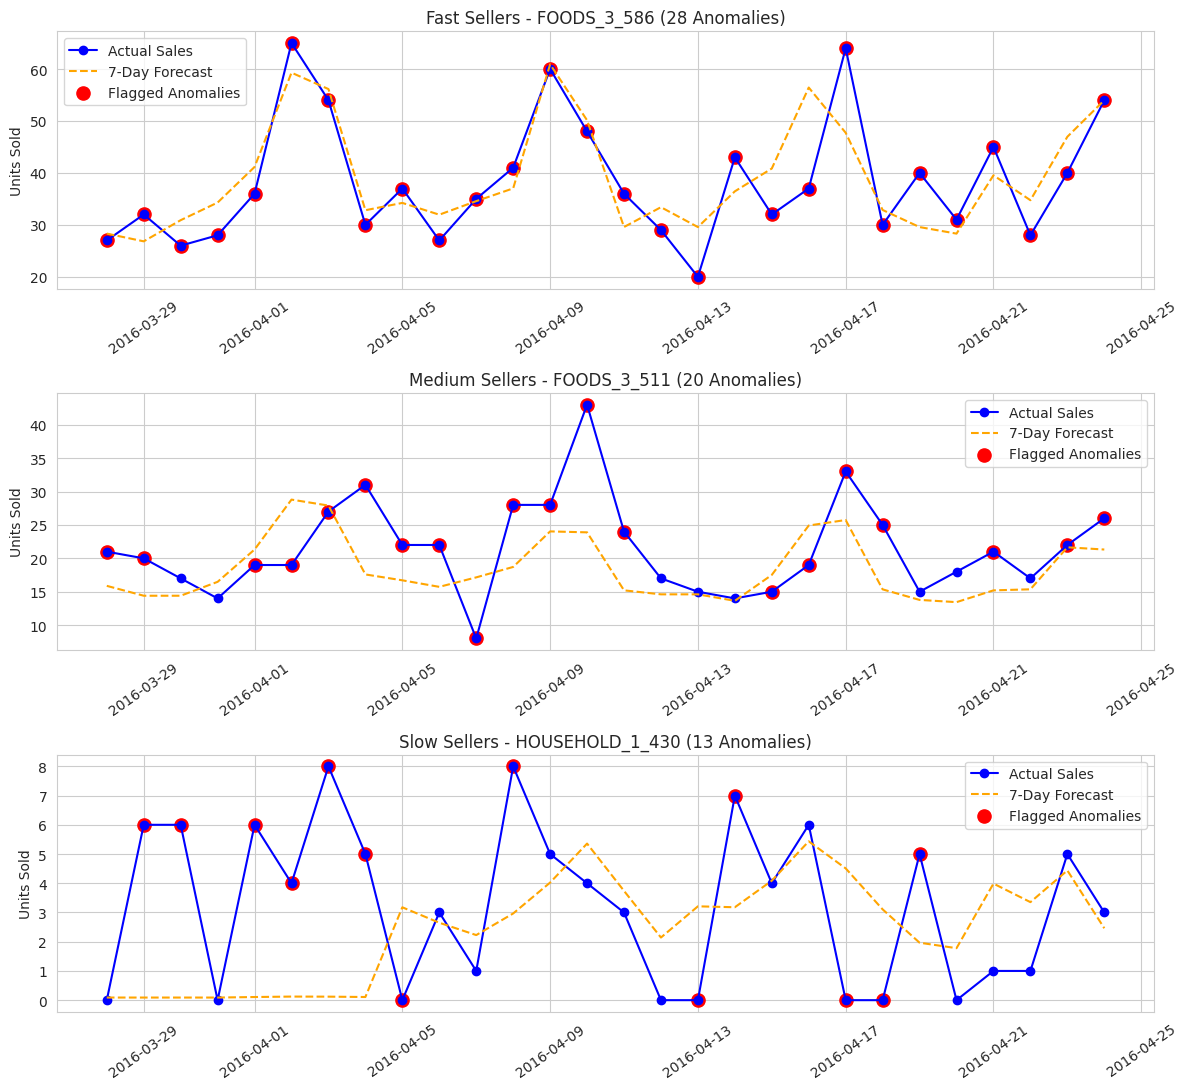

In [ ]:
# Step 12: Plot Sample Item Sales with Flagged Anomalies

# Select one item from each group that has anomalies
sample_items = []

groups = ["Fast Sellers", "Medium Sellers", "Slow Sellers"]

for group in groups:

    # Get anomalies from the current group
    group_anomalies = val_df[
        (val_df["group"] == group) & (val_df["is_anomaly"])
    ]

    # Select the item with the most anomalies
    if not group_anomalies.empty:
        item_id = group_anomalies["item_id"].value_counts().idxmax()
        sample_items.append((group, item_id))


# Create one chart for each selected item
fig, axes = plt.subplots(
    len(sample_items), 1,
    figsize=(12, 11)
)

# Handle the case where only one item is selected
if len(sample_items) == 1:
    axes = [axes]


for i, (group, item_id) in enumerate(sample_items):

    # Get sales data for the selected item
    item_data = val_df[val_df["item_id"] == item_id].sort_values("date")

    # Get only the flagged anomaly days
    anomalies = item_data[item_data["is_anomaly"]]

    # Plot actual sales
    axes[i].plot(
        item_data["date"],
        item_data["sales"],
        label="Actual Sales",
        color="blue",
        marker="o"
    )

    # Plot forecasted sales
    axes[i].plot(
        item_data["date"],
        item_data["forecast"],
        label="7-Day Forecast",
        color="orange",
        linestyle="--"
    )

    # Highlight anomaly days with red dots
    axes[i].scatter(
        anomalies["date"],
        anomalies["sales"],
        color="red",
        s=90,
        label="Flagged Anomalies"
    )

    # Add chart title and labels
    axes[i].set_title(
        f"{group} - {item_id} ({len(anomalies)} Anomalies)"
    )

    axes[i].set_ylabel("Units Sold")
    axes[i].legend()
    axes[i].tick_params(axis="x", rotation=35)


plt.tight_layout()
plt.show()

## **Step 13: Export Validation Results and Trained Models to Google Drive**

### **What we are doing**

We are connecting Google Drive, creating a DemandLens folder, and saving our validation results and trained models:

1. `anomalies_validation.parquet` – Validation anomaly results with 10 required columns.
2. `item_groups.csv` – K-Means groups assigned to each item.
3. `group_thresholds.csv` – Anomaly thresholds for each group.
4. `kmeans_model.joblib` – Trained K-Means model.
5. `kmeans_scaler.joblib` – Scaler for new items.
6. `isolation_forest_model.joblib` – Trained Isolation Forest model.

### **Why we need this step**

Google Colab storage is temporary, so files can be lost when the session ends. Google Drive allows us to keep our results and models محفوظ for future use.

### **What problem this solves**

It prevents losing our trained models and ensures the exported validation file follows the exact 10-column format required by the DemandLens backend.

### **Expected output**

- Google Drive mounting confirmation.
- A `[SAVED]` message for each exported file.
- File sizes displayed in KB or MB.

**Note:** `anomalies_test.parquet` will be exported separately in Step 14 after final testing.

In [ ]:
# Step 13: Export Validation Results and Trained Models

# Make sure the export folder exists
os.makedirs(EXPORT_DIR, exist_ok=True)

print(f"Saving files to: {EXPORT_DIR}\n")


# 1. Export validation anomaly results with exactly 10 columns
required_cols = [
    "item_id", "date", "sales", "forecast", "residual",
    "direction", "group", "is_anomaly", "flagged_by", "reason"
]

anomalies_val_export = val_df[required_cols].copy()

val_path = os.path.join(EXPORT_DIR, "anomalies_validation.parquet")
anomalies_val_export.to_parquet(val_path, index=False)


# 2. Export item groups
item_cols = [
    "item_id", "avg_sales", "zero_sales_share",
    "sales_std", "weekend_sales_ratio", "group"
]

item_path = os.path.join(EXPORT_DIR, "item_groups.csv")
item_features[item_cols].to_csv(item_path, index=False)


# 3. Export group thresholds
threshold_path = os.path.join(EXPORT_DIR, "group_thresholds.csv")
group_thresholds.to_csv(threshold_path, index=False)


# 4. Export K-Means model and scaler
kmeans_path = os.path.join(EXPORT_DIR, "kmeans_model.joblib")
scaler_path = os.path.join(EXPORT_DIR, "kmeans_scaler.joblib")

joblib.dump(kmeans_model, kmeans_path)
joblib.dump(scaler, scaler_path)


# 5. Export Isolation Forest model
iso_path = os.path.join(EXPORT_DIR, "isolation_forest_model.joblib")
joblib.dump(iso_model, iso_path)


# 6. Verify all exported files
saved_files = [
    val_path,
    item_path,
    threshold_path,
    kmeans_path,
    scaler_path,
    iso_path
]

print("--- Export Verification ---")

for file in saved_files:
    size_kb = os.path.getsize(file) / 1024
    print(f"[SAVED] {os.path.basename(file):<32} ({size_kb:,.1f} KB)")


# 7. Verify validation file columns
print("\n--- Validation File Columns ---")
print(anomalies_val_export.columns.tolist())


# 8. Display all files in the export folder
print("\n--- Files in Export Folder ---")
print(os.listdir(EXPORT_DIR))

Saving files to: /content/drive/MyDrive/DemandLens/Data/processed

--- Export Verification ---
[SAVED] anomalies_validation.parquet     (1,604.2 KB)
[SAVED] item_groups.csv                  (307.7 KB)
[SAVED] group_thresholds.csv             (0.2 KB)
[SAVED] kmeans_model.joblib              (12.7 KB)
[SAVED] kmeans_scaler.joblib             (1.0 KB)
[SAVED] isolation_forest_model.joblib    (998.7 KB)

--- Validation File Columns ---
['item_id', 'date', 'sales', 'forecast', 'residual', 'direction', 'group', 'is_anomaly', 'flagged_by', 'reason']

--- Files in Export Folder ---
['CA_1_merged.parquet', 'CA_1_clean.parquet', 'ca1_h7_train.parquet', 'ca1_h28_train.parquet', 'ca1_h7_val.parquet', 'ca1_h28_val.parquet', 'lightgbm_h7.joblib', 'feature_lists.json', 'h7_val_predictions.parquet', 'lightgbm_h28.joblib', 'anomalies_validation.parquet', 'item_groups.csv', 'group_thresholds.csv', 'kmeans_model.joblib', 'kmeans_scaler.joblib', 'isolation_forest_model.joblib']
